**Detecção de Veículos e Leitura de Placas (OCR)**

Este notebook demonstra um fluxo de trabalho de Visão Computacional para identificar veículos e extrair o texto de suas placas. O processo é dividido em três etapas principais:


* Detecção de Objetos: Utiliza o modelo YOLOv8 para localizar carros e caminhões em uma imagem carregada.
* Processamento de Imagem: Realiza o recorte automático dos veículos detectados para isolar a área de interesse.
* Reconhecimento Óptico de Caracteres (OCR): Emprega a biblioteca EasyOCR para ler e converter os caracteres das placas em texto digital.




In [1]:
# 1. Instale a biblioteca de leitura de texto (OCR)
!pip install easyocr ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.6/300.6 kB 23.9 MB/s eta 0:00:00


# Carregando OCR e modelo de detecção

In [2]:
import easyocr
from ultralytics import YOLO

# 2. Inicializa o 'leitor' de texto e o modelo de detecção
reader = easyocr.Reader(['en']) # 'en' funciona bem para placas brasileiras (letras/números)
modelo = YOLO('yolov8s.pt') # carrega o modelo de detecção de objetos YOLO small

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

# Exemplo - Detectando veículos e tentando reconhecer placas



Selecione a imagem com carros com placas:


Saving gettyimages-1399888792-612x612.jpg to gettyimages-1399888792-612x612.jpg


ENTRADA: Imagem Original


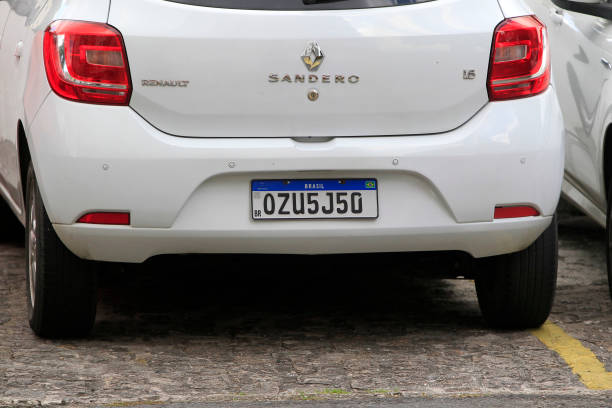


image 1/1 /content/gettyimages-1399888792-612x612.jpg: 448x640 2 cars, 643.3ms
Speed: 14.7ms preprocess, 643.3ms inference, 34.6ms postprocess per image at shape (1, 3, 448, 640)


SAÍDA: O que a IA enxerga


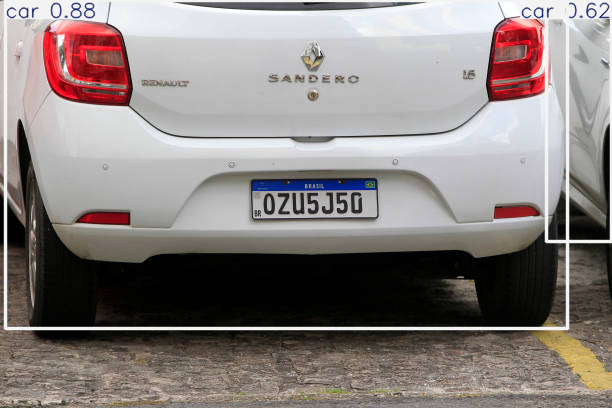



--- RESULTADO DA LEITURA ---


Recorte


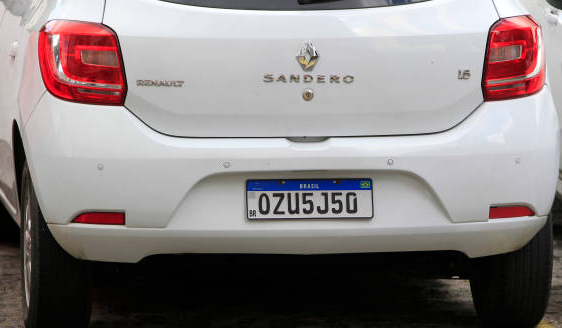

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


📌 Possível Placa Detectada: 442IR8 (Confiança: 9.24%)
📌 Possível Placa Detectada: 0ZU5550 (Confiança: 31.40%)


Recorte


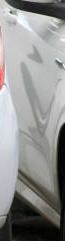

❌ Nenhuma placa encontrada


In [3]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# 3. Upload da imagem do carro
print("\n\nSelecione a imagem com carros com placas:")
uploaded = files.upload()
foto = list(uploaded.keys())[0]

# Mostra a imagem caregada
imagem = cv2.imread(foto)
print("\n\nENTRADA: Imagem Original")
cv2_imshow(imagem)

# 4. A IA procura o carro e a placa
resultados = modelo.predict(foto, conf=0.4)

# Imagem com a "Visão da IA" (Caixas e Nomes)
img_ia = resultados[0].plot()
print("\n\nSAÍDA: O que a IA enxerga")
cv2_imshow(img_ia)

print("\n\n--- RESULTADO DA LEITURA ---")

# Para cada objeto reconhecido
for res in resultados[0].boxes:
    # Se a IA achar um 'car' (carro) ou 'truck' (caminhão)
    if res.cls[0] in [2, 7]:
        x1, y1, x2, y2 = map(int, res.xyxy[0])
        carro_recortado = cv2.imread(foto)[y1:y2, x1:x2]

        print("\n\nRecorte")
        cv2_imshow(carro_recortado)

        # O EasyOCR tenta ler qualquer texto dentro da área do carro
        leitura = reader.readtext(carro_recortado)

        if (leitura):
          for (bbox, texto, conf) in leitura:
              # Filtro simples: placas geralmente têm entre 4 e 8 caracteres
              if len(texto) > 3:
                  print(f"📌 Possível Placa Detectada: {texto.upper()} (Confiança: {conf:.2%})")
        else:
          print("❌ Nenhuma placa encontrada")